# ANSUR II | Women's and Men's Height Distributions & Decision Tree Bagging

**Exercise 6 — Classification, Bootstrap Aggregation, and Model Evaluation**  
**Dataset:** [ANSUR II — OpenLab](https://www.openlab.psu.edu/ansur2) · [ANSUR II — Kaggle](https://www.kaggle.com/datasets/seshadrikolluri/ansur-ii)  
**Method:** Single Decision Tree vs. `BaggingClassifier(estimator=DecisionTreeClassifier(...))`

## Research objective

The **Anthropometric Survey of U.S. Army Personnel (ANSUR II)** contains body measurements and additional respondent information. This notebook examines the height distributions for the dataset's `Female` and `Male` groups and tests whether **bootstrap aggregation (bagging)** improves the classification performance of a standalone Decision Tree.

**Target assumption:** The assignment does not explicitly specify a classification label. The existing code therefore predicts the dataset's binary `Gender` field from **93 numeric anthropometric measurements**, while excluding identifiers and demographic/administrative fields. These labels describe the source dataset; anthropometric measurements must not be interpreted as a reliable means of establishing a person's gender identity.

### Analysis workflow

| Part | Requirement | Evidence |
|:--|:--|:--|
| **A** | Obtain the ANSUR II data | Section 1 — load both supplied CSV files |
| **B** | Preprocess and clean the dataset | Sections 2, 3, and 6 — schema harmonization, data-quality checks, and training-only diagnostics |
| **C** | Plot height distributions together; answer two questions in 2–3 sentences | Section 5 — shared-bin histogram, concise interpretation, and a density-normalized companion plot |
| **D** | 80% training / 20% test split | Section 4 — stratified `train_test_split` with `random_state=42` |
| **E** | Bag a Decision Tree; compare against one Decision Tree | Sections 8–9 — specified estimators and training-only cross-validation |
| **F** | Report test accuracy | Section 10 — final comparison on the reserved test set |
| **G** | Compute a test confusion matrix | Section 11 — labeled confusion matrices for both models |

### Key recorded results

| Held-out test metric | Decision Tree | Bagging + Decision Tree |
|:--|--:|--:|
| Accuracy | **97.86%** | **98.76%** |
| Misclassified participants | **26** | **15** |

These values are taken from the notebook's **saved execution outputs**; they are not predictions about future runs.

> **Evaluation integrity:** The test partition is held out from model fitting, preprocessing decisions, and cross-validation. Both models use the same split and the same 93 measurements; test results are reported only after the modeling workflow is established. `RandomForestClassifier` is **not** used anywhere in the code.

---

## 1. Environment, imports, and source-data loading — **Part A**

This cell imports the numerical, visualization, and `scikit-learn` libraries required throughout the notebook and fixes the random seed at **42** for reproducibility.

The ANSUR II female and male CSV files are supplied separately. The loader searches the current working directory and `/mnt/data`, accommodates the supplied filename variants, and reads the files with **`cp1252` encoding**. It displays the source filenames and table shapes so that the loaded dataset can be verified before processing.

**Recorded source dimensions:** 1,986 female observations and 4,082 male observations, each with 108 source columns. Running this notebook locally requires the two original CSVs to be available alongside it or in one of the coded search locations.

In [1]:
from pathlib import Path
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)
sns.set_theme(style='whitegrid', context='notebook')

print(f'Python: {platform.python_version()}')
print(f'Pandas: {pd.__version__} | Scikit-learn: {sklearn.__version__}')

def find_data_file(sex: str) -> Path:
    directories = [Path.cwd(), Path('/mnt/data')]
    priority_names = [
        f'ANSUR_II_{sex}_Public(3).csv',
        f'ANSUR_II_{sex}_Public.csv',
    ]
    for directory in directories:
        for name in priority_names:
            candidate = directory / name
            if candidate.is_file():
                return candidate
    for directory in directories:
        matches = sorted(directory.glob(f'ANSUR_II_{sex}_Public*.csv'))
        if matches:
            return matches[-1]
    raise FileNotFoundError(
        f'Missing ANSUR II {sex} CSV. Place the provided dataset files alongside this notebook.'
    )

female_file = find_data_file('FEMALE')
male_file = find_data_file('MALE')
female_raw = pd.read_csv(female_file, encoding='cp1252', low_memory=False)
male_raw = pd.read_csv(male_file, encoding='cp1252', low_memory=False)
print(f'Female file: {female_file.name}; shape: {female_raw.shape}')
print(f'Male file:   {male_file.name}; shape: {male_raw.shape}')

Python: 3.11.0
Pandas: 2.3.3 | Scikit-learn: 1.9.1
Female file: ANSUR_II_FEMALE_Public.csv; shape: (1986, 108)
Male file:   ANSUR_II_MALE_Public.csv; shape: (4082, 108)


## 2. Data inspection and structural cleaning — **Part B**

The first preparation step checks the table schemas, representative values, column types, missingness, and duplicate records. In the source files, the participant identifier is named `SubjectId` in one table and `subjectid` in the other; the code standardizes the name to prevent the combined table from treating them as different fields.

After column alignment, the two tables are concatenated into a single **6,068-row** dataset. The code also verifies that the supplied class labels match the corresponding source files, and explicitly checks full-row duplicates and repeated participant identifiers.

**Recorded quality audit:** zero duplicate records and zero repeated subject IDs. The `Ethnicity` field contains 4,647 missing entries, but it is not a predictor in the eventual anthropometric-only model; there is no reason to impute it for this task.

In [2]:
print('Female identifier column:', female_raw.columns[0])
print('Male identifier column:  ', male_raw.columns[0])
print('\nFemale example rows:')
display(female_raw[['SubjectId', 'stature', 'weightkg', 'Gender']].head(3))
print('Male example rows:')
display(male_raw[['subjectid', 'stature', 'weightkg', 'Gender']].head(3))
print('Female dtypes:', female_raw.dtypes.value_counts().to_dict())
print('Male dtypes:', male_raw.dtypes.value_counts().to_dict())

female = female_raw.rename(columns={'SubjectId': 'subjectid'}).copy()
male = male_raw.rename(columns={'SubjectId': 'subjectid'}).copy()

assert female.columns.is_unique and male.columns.is_unique, 'Duplicate column names detected.'
assert set(female.columns) == set(male.columns), 'The CSVs have different sets of columns.'
assert female['Gender'].eq('Female').all(), 'Unexpected labels in the female file.'
assert male['Gender'].eq('Male').all(), 'Unexpected labels in the male file.'

# Reindex to guarantee correct alignment when concatenating the two source files.
male = male.reindex(columns=female.columns)
df = pd.concat([female, male], axis=0, ignore_index=True)
assert df['subjectid'].notna().all(), 'Some records lack subject identifiers.'
assert df['Gender'].isin(['Female', 'Male']).all(), 'Unexpected target labels.'

print(f'Combined dataset: {df.shape[0]:,} rows × {df.shape[1]} columns')
print('Gender counts:')
display(df['Gender'].value_counts().rename_axis('Gender').to_frame('Count'))
print('Gender percentages:')
display((100 * df['Gender'].value_counts(normalize=True)).round(2).rename('Percent'))

Female identifier column: SubjectId
Male identifier column:   subjectid

Female example rows:


,SubjectId,stature,weightkg,Gender
0,10037,1560,657,Female
1,10038,1665,534,Female
2,10042,1711,663,Female


Male example rows:


,subjectid,stature,weightkg,Gender
0,10027,1776,815,Male
1,10032,1702,726,Male
2,10033,1735,929,Male


Female dtypes: {dtype('int64'): 99, dtype('O'): 9}
Male dtypes: {dtype('int64'): 99, dtype('O'): 9}
Combined dataset: 6,068 rows × 108 columns
Gender counts:


,Count
Gender,
Male,4082
Female,1986


Gender percentages:


Gender
Male      67.27
Female    32.73
Name: Percent, dtype: float64

In [3]:
full_row_duplicates = int(df.duplicated().sum())
subject_id_duplicates = int(df['subjectid'].duplicated().sum())
missing_counts = df.isna().sum().sort_values(ascending=False)
missing_audit = pd.DataFrame({
    'Missing count': missing_counts,
    'Missing %': (100 * missing_counts / len(df)).round(2),
})

print(f'Exact duplicate rows: {full_row_duplicates}')
print(f'Duplicate subject identifiers: {subject_id_duplicates}')
print('Columns with missing values:')
display(missing_audit.loc[missing_audit['Missing count'] > 0])
print('Data type counts after merging:')
display(df.dtypes.astype(str).value_counts().rename('Number of columns'))
print('Total number of columns:', len(df.columns))
print('Preview of descriptive statistics for selected measurements:')
display(df[['stature', 'weightkg', 'handlength', 'footlength']].describe().round(2))

assert full_row_duplicates == 0, 'Review duplicate records before splitting.'
assert subject_id_duplicates == 0, 'Resolve repeated subjects before splitting.'

Exact duplicate rows: 0
Duplicate subject identifiers: 0
Columns with missing values:


,Missing count,Missing %
Ethnicity,4647,76.58


Data type counts after merging:


int64     99
object     9
Name: Number of columns, dtype: int64

Total number of columns: 108
Preview of descriptive statistics for selected measurements:


,stature,weightkg,handlength,footlength
count,6068.00,6068.00,6068.00,6068.00
mean,1714.41,797.09,189.29,263.03
std,90.02,156.53,11.51,17.39
min,1409.00,358.00,145.00,198.00
25%,1651.75,682.00,181.00,251.00
50%,1719.00,785.00,189.50,264.00
75%,1779.00,896.00,197.00,276.00
max,1993.00,1442.00,239.00,323.00


### Cleaning decision and rationale

The necessary correction is **schema harmonization**, not indiscriminate deletion or imputation. The identifier spelling is unified, columns are aligned by name, and the source rows are retained because no exact duplicate records or repeated identifiers were detected. Missing entries in excluded administrative fields are documented rather than filled without a modeling purpose.

> **Leakage safeguard:** No target-driven feature selection, learned normalization, outlier cutoff, or imputation statistic is derived from the combined dataset before the train/test split.

## 3. Define the prediction target and modeling features

The classifier predicts the source dataset's **`Gender`** label (`Female` or `Male`). The existing code identifies a contiguous, schema-defined block of **93 measured anthropometric variables**, starting at `abdominalextensiondepthsitting` and ending at `wristheight`.

This feature selection intentionally excludes the subject identifier, target label, and auxiliary demographic or administrative columns such as `Date`, `Ethnicity`, `Age`, `Heightin`, and `Weightlbs`. The resulting `X` matrix contains numeric measurements only; `y` contains the original dataset labels.

**Height unit:** `stature` is a measured height in **millimeters**. It is divided by 10 solely for the height plots in centimeters; the model uses the original numeric measurement columns supplied by the code.

Because the feature set is selected from a fixed column layout rather than from the relationship between features and the target, this step does not use the test labels to choose predictors.

In [4]:
feature_start = df.columns.get_loc('abdominalextensiondepthsitting')
feature_end = df.columns.get_loc('wristheight')
measurement_features = df.columns[feature_start:feature_end + 1].tolist()

assert len(measurement_features) == 93, (
    f'Expected 93 anthropometric measurements; found {len(measurement_features)}.'
)
assert 'stature' in measurement_features and 'weightkg' in measurement_features
assert 'Gender' not in measurement_features and 'subjectid' not in measurement_features
assert all(pd.api.types.is_numeric_dtype(df[col]) for col in measurement_features), (
    'A selected anthropometric feature is not numeric; investigate before training.'
)

X = df.loc[:, measurement_features].copy()
y = df['Gender'].copy()

print(f'Features: {X.shape[1]} numeric measurements | Target: {y.name}')
print('First ten features:', measurement_features[:10])
print('Last ten features:', measurement_features[-10:])
print('Excluded auxiliary columns:', [c for c in df if c not in measurement_features and c != 'Gender'])

Features: 93 numeric measurements | Target: Gender
First ten features: ['abdominalextensiondepthsitting', 'acromialheight', 'acromionradialelength', 'anklecircumference', 'axillaheight', 'balloffootcircumference', 'balloffootlength', 'biacromialbreadth', 'bicepscircumferenceflexed', 'bicristalbreadth']
Last ten features: ['verticaltrunkcircumferenceusa', 'waistbacklength', 'waistbreadth', 'waistcircumference', 'waistdepth', 'waistfrontlengthsitting', 'waistheightomphalion', 'weightkg', 'wristcircumference', 'wristheight']
Excluded auxiliary columns: ['subjectid', 'Date', 'Installation', 'Component', 'Branch', 'PrimaryMOS', 'SubjectsBirthLocation', 'SubjectNumericRace', 'Ethnicity', 'DODRace', 'Age', 'Heightin', 'Weightlbs', 'WritingPreference']


## 4. Stratified 80/20 train–test split — **Part D**

An **80% / 20%** split is created with `train_test_split`, `test_size=0.20`, `random_state=42`, and `stratify=y`. Stratification approximately preserves the observed `Female`/`Male` label proportions in both partitions, making the evaluation more interpretable under unequal class sizes.

| Partition | Records | Female | Male |
|:--|--:|--:|--:|
| **Training** | 4,854 | 1,589 | 3,265 |
| **Test** | 1,214 | 397 | 817 |

All training-dependent diagnostics, model training, and five-fold cross-validation that follow are restricted to the **training partition**. The test partition is reserved for the final reported evaluation.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
assert set(X_train.index).isdisjoint(set(X_test.index)), 'Train and test indices overlap.'

print(f'Training: X={X_train.shape}; y={y_train.shape}')
print(f'Test:     X={X_test.shape}; y={y_test.shape}')

class_split_table = pd.DataFrame({
    'Train count': y_train.value_counts(),
    'Train %': (100 * y_train.value_counts(normalize=True)).round(2),
    'Test count': y_test.value_counts(),
    'Test %': (100 * y_test.value_counts(normalize=True)).round(2),
}).reindex(['Female', 'Male'])
display(class_split_table)

Training: X=(4854, 93); y=(4854,)
Test:     X=(1214, 93); y=(1214,)


,Train count,Train %,Test count,Test %
Gender,,,,
Female,1589,32.74,397,32.7
Male,3265,67.26,817,67.3


## 5. Height distributions on the same figure — **Part C**

The code uses the **training subset only** to compare measured heights in centimeters. Both dataset groups are plotted on the **same axes with identical histogram bins**, allowing differences in observed count and horizontal location to be interpreted separately.

The first figure is a **count histogram**: its bar heights depend on both sample size and the number of participants in a height interval. A second, **density-normalized** histogram is supplied as an additional diagnostic; it removes the direct effect of group size on total histogram area.

**Recorded training-set summary:**

| Dataset label | Participants | Mean height (cm) | Median height (cm) |
|:--|--:|--:|--:|
| Female | 1,589 | 162.83 | 162.60 |
| Male | 3,265 | 175.58 | 175.40 |

The requested short answer appears immediately after the count-based histogram.

Height summary — training data only:


,count,mean,std,median
Gender,,,,
Female,1589,162.83,6.37,162.6
Male,3265,175.58,6.83,175.4


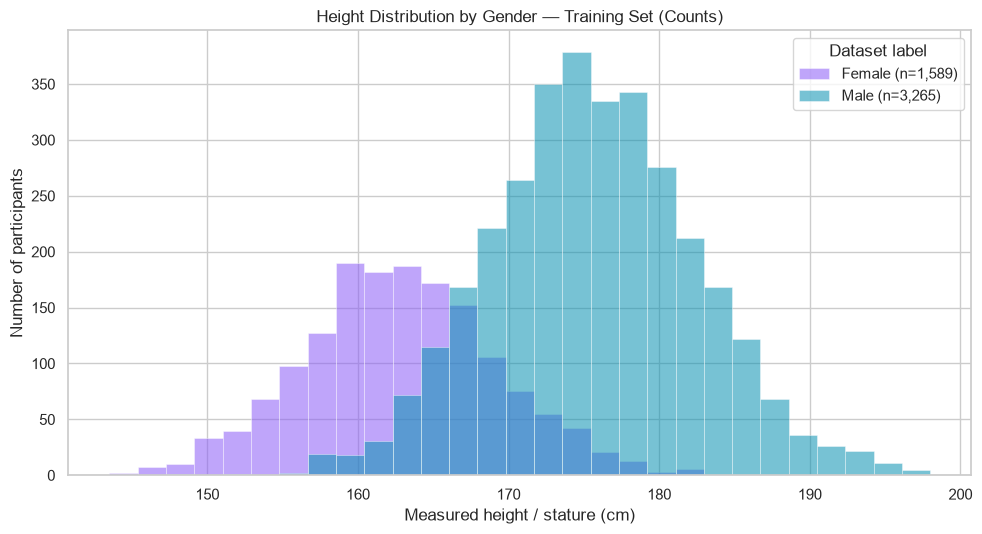

In [6]:
height_train = pd.DataFrame({
    'Height (cm)': X_train['stature'] / 10.0,
    'Gender': y_train,
})
height_summary = height_train.groupby('Gender')['Height (cm)'].agg(['count','mean','std','median']).round(2)
print('Height summary — training data only:')
display(height_summary)

same_bins = np.linspace(height_train['Height (cm)'].min(),
                        height_train['Height (cm)'].max(), 30)
colors = {'Female': '#8b5cf6', 'Male': '#0891b2'}

fig, ax = plt.subplots(figsize=(10, 5.5))
for label in ['Female', 'Male']:
    values = height_train.loc[height_train['Gender'].eq(label), 'Height (cm)']
    ax.hist(values, bins=same_bins, alpha=0.55, label=f'{label} (n={len(values):,})',
            color=colors[label], edgecolor='white', linewidth=0.5)
ax.set(title='Height Distribution by Gender — Training Set (Counts)',
       xlabel='Measured height / stature (cm)', ylabel='Number of participants')
ax.legend(title='Dataset label')
fig.tight_layout()
plt.show()

### Part C — Required answer (three sentences)

The men's bars are generally **higher in the count histogram** because there are **3,265 male participants versus 1,589 female participants** in the training subset, producing more observations in many height bins. The men's height distribution is shifted **farther to the right** because the mean measured height of the male group is **175.58 cm**, compared with **162.83 cm** for the female group in this dataset. The difference in bar height primarily reflects **unequal sample sizes**, whereas the horizontal shift reflects the observed **height distributions**, which still overlap.

**Interpretation note:** Density normalization in the next figure makes group shapes more directly comparable without making broad claims about all women or men outside this specific military sample.

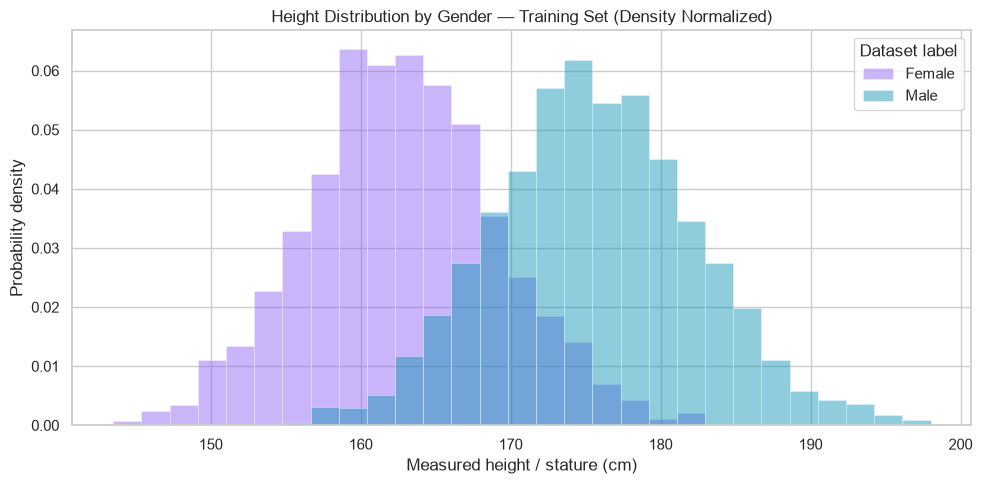

Density normalization makes the histogram areas comparable despite different sample sizes.


In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
for label in ['Female', 'Male']:
    values = height_train.loc[height_train['Gender'].eq(label), 'Height (cm)']
    ax.hist(values, bins=same_bins, density=True, alpha=0.45,
            label=label, color=colors[label], edgecolor='white', linewidth=0.5)
ax.set(title='Height Distribution by Gender — Training Set (Density Normalized)',
       xlabel='Measured height / stature (cm)', ylabel='Probability density')
ax.legend(title='Dataset label')
fig.tight_layout()
plt.show()
print('Density normalization makes the histogram areas comparable despite different sample sizes.')

## 6. Preprocessing audit using training data only — **Part B, continued**

Good preprocessing is based on a demonstrated data-quality need, not on automatically applying every possible transformation. This cell inspects the **selected training features** for missing data, nonnumeric variables, nonpositive measurements, and potential extreme values using a descriptive **1.5 × interquartile range (IQR)** rule.

- **Missingness:** The 93 selected predictors have no missing training values, so no imputation is required.
- **Data types:** The predictors are numeric, so there is no need to encode categorical input features.
- **Scale:** Decision Trees and bagged trees partition observations by thresholds; standardization is not required for this implementation.
- **Potential outliers:** IQR-flagged values are investigated descriptively, not automatically removed. Anthropometric extremes are not necessarily incorrect observations.

Crucially, any statistical filling, filtering, or other fitted preprocessing introduced in a future experiment would need to be learned **within the training split or cross-validation folds**, not from the reserved test data.

In [8]:
train_missing = X_train.isna().sum()
non_numeric = X_train.select_dtypes(exclude=np.number).columns.tolist()
non_positive = (X_train <= 0).sum()

print(f'Training missing values across measurement features: {int(train_missing.sum())}')
print(f'Non-numeric selected features: {non_numeric}')
print(f'Measurement features containing nonpositive values: {int((non_positive > 0).sum())}')

q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
outlier_counts = (X_train.lt(q1 - 1.5 * iqr) |
                  X_train.gt(q3 + 1.5 * iqr)).sum().sort_values(ascending=False)
print('Top 10 measurement columns by exploratory 1.5×IQR flagged values (TRAIN ONLY):')
display(outlier_counts.head(10).rename('Flagged measurements').to_frame())

assert not non_numeric, 'Unexpected nonnumeric model features.'
assert train_missing.sum() == 0, 'If missingness appears, use a train-fitted imputer pipeline.'
assert (non_positive == 0).all(), 'Review physically impossible nonpositive measurements.'
print('Decision: No imputation, scaling, encoding, or automatic outlier removal is needed.')

Training missing values across measurement features: 0
Non-numeric selected features: []
Measurement features containing nonpositive values: 0
Top 10 measurement columns by exploratory 1.5×IQR flagged values (TRAIN ONLY):


,Flagged measurements
interpupillarybreadth,90
hipbreadth,65
bicristalbreadth,62
lowerthighcircumference,61
palmlength,59
hipbreadthsitting,58
thighcircumference,50
thighclearance,49
headbreadth,48
buttockcircumference,47


Decision: No imputation, scaling, encoding, or automatic outlier removal is needed.


## 7. Inspect class balance before model training

The two labels are **not equally frequent**: the training set contains approximately **67.26% Male** and **32.74% Female** observations. An accuracy score alone can conceal uneven class-level performance, so the notebook also reports **balanced accuracy**, **macro-averaged precision/recall/F1**, per-class classification reports, and confusion matrices.

This assignment specifically asks for a comparison between a Decision Tree and its bagged counterpart, **not** for resampling. The current code intentionally does not introduce synthetic samples or class-rebalancing steps that would change the experimental comparison. Any future resampling experiment should be implemented inside training folds to prevent leakage.

In [9]:
training_counts = y_train.value_counts().reindex(['Female','Male'])
training_percent = 100 * training_counts / len(y_train)
display(pd.DataFrame({'Train count':training_counts, 'Share (%)':training_percent.round(2)}))
print(f'Majority/minority ratio: {training_counts.max() / training_counts.min():.2f}:1')
print('Resampling policy: no SMOTE or oversampling in the primary model comparison.')

,Train count,Share (%)
Gender,,
Female,1589,32.74
Male,3265,67.26


Majority/minority ratio: 2.05:1
Resampling policy: no SMOTE or oversampling in the primary model comparison.


## 8. Single Decision Tree vs. Bootstrap Aggregation — **Part E**

### Baseline: `DecisionTreeClassifier`

A Decision Tree learns a sequence of feature-threshold decisions. A single unrestricted tree can fit its training observations closely but may be sensitive to changes in the training sample.

### Ensemble: `BaggingClassifier`

**Bootstrap Aggregation (bagging)** repeatedly draws bootstrap samples **with replacement** from the training data, fits a Decision Tree to each sample, and combines their predictions for classification. By averaging the behavior of multiple trees through voting, bagging can reduce prediction variance; whether this improves measured accuracy must be checked empirically.

| Setting | Baseline | Bagged model |
|:--|:--|:--|
| Estimator | `DecisionTreeClassifier` | `BaggingClassifier` with `DecisionTreeClassifier` base estimator |
| Number of fitted trees | 1 | **100** |
| Bootstrap resampling | No | **Yes** |
| Random seed | `42` | `42` |
| Train/test split | Same 80/20 partition | Same 80/20 partition |

**Constraint satisfied:** The code uses **`BaggingClassifier` and `DecisionTreeClassifier`**, never `RandomForestClassifier`. No grid search or other changes are introduced into the provided model definitions.

In [10]:
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Bagging + Decision Tree': BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100,
        bootstrap=True,
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
}
print('Baseline:', models['Decision Tree'])
print('Ensemble:', models['Bagging + Decision Tree'])

Baseline: DecisionTreeClassifier(random_state=42)
Ensemble: BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),
                  n_estimators=100, n_jobs=1, random_state=42)


## 9. Fair model comparison: cross-validation restricted to training data

Before opening the test results, both pre-specified estimators are evaluated using **five-fold stratified cross-validation** within the 80% training partition. The same shuffled folds and `random_state=42` are used for both models.

The code computes the **mean and standard deviation** of cross-validation accuracy, balanced accuracy, and macro F1. The preferred model is selected by **mean macro F1**, which gives equal consideration to both source labels despite their different frequencies.

> **Why this matters:** Choosing a model based on the test set would compromise the test set's role as independent evidence. In this notebook, model preference is established from training-only cross-validation; the held-out test set is used afterward for final evaluation.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'Accuracy': 'accuracy',
           'Balanced accuracy': 'balanced_accuracy',
           'Macro F1': 'f1_macro'}
cv_rows = []
for model_name, estimator in models.items():
    result = cross_validate(
        estimator, X_train, y_train,
        cv=cv, scoring=scoring, return_train_score=False,
        n_jobs=1, error_score='raise',
    )
    row = {'Model': model_name}
    for metric_name in scoring:
        values = result['test_' + metric_name]
        row[f'{metric_name} mean'] = values.mean()
        row[f'{metric_name} std'] = values.std(ddof=1)
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).set_index('Model')
print('Training-only 5-fold stratified CV (higher is better):')
display(cv_results.style.format('{:.4f}'))

preferred_model_name = cv_results['Macro F1 mean'].idxmax()
print(f'Preferred model by mean CV macro F1 (chosen before test): {preferred_model_name}')

Training-only 5-fold stratified CV (higher is better):


,Accuracy mean,Accuracy std,Balanced accuracy mean,Balanced accuracy std,Macro F1 mean,Macro F1 std
Model,,,,,,
Decision Tree,0.9763,0.0053,0.9732,0.0053,0.9731,0.0060
Bagging + Decision Tree,0.9870,0.0059,0.9849,0.0064,0.9853,0.0067


Preferred model by mean CV macro F1 (chosen before test): Bagging + Decision Tree


## 10. Final evaluation on the held-out test set — **Part F**

Each model is trained on the complete **4,854-row training partition** and then evaluated on the same **1,214 previously unseen test records**. **Accuracy** is the assignment's required metric; balanced accuracy, macro precision, macro recall, macro F1, and full classification reports provide a richer diagnostic.

\[
\text{Accuracy} = \frac{\text{Number of correct predictions}}{\text{Number of test observations}}
\]

The following code displays the model-by-model results. The notebook retains the actual saved outputs rather than treating bagging as guaranteed to outperform the baseline.

In [12]:
test_predictions = {}
final_rows = []
per_class_reports = {}

for model_name, estimator in models.items():
    estimator.fit(X_train, y_train)
    predicted = estimator.predict(X_test)
    test_predictions[model_name] = predicted
    final_rows.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predicted),
        'Balanced accuracy': balanced_accuracy_score(y_test, predicted),
        'Macro precision': precision_score(y_test, predicted, average='macro', zero_division=0),
        'Macro recall': recall_score(y_test, predicted, average='macro', zero_division=0),
        'Macro F1': f1_score(y_test, predicted, average='macro', zero_division=0),
    })
    per_class_reports[model_name] = classification_report(
        y_test, predicted, labels=['Female','Male'], output_dict=True, zero_division=0
    )

test_results = pd.DataFrame(final_rows).set_index('Model')
print('Held-out test performance (fraction of 1.0; higher is better):')
display(test_results.style.format('{:.4f}'))
print('\nTest accuracies required by assignment:')
for model_name in models:
    print(f'{model_name}: {test_results.loc[model_name, "Accuracy"]:.4f} '
          f'({100 * test_results.loc[model_name, "Accuracy"]:.2f}%)')

for model_name, predicted in test_predictions.items():
    print(f'\nClassification report — {model_name}:')
    print(classification_report(y_test, predicted, labels=['Female', 'Male'], digits=4, zero_division=0))

Held-out test performance (fraction of 1.0; higher is better):


,Accuracy,Balanced accuracy,Macro precision,Macro recall,Macro F1
Model,,,,,
Decision Tree,0.9786,0.9711,0.9801,0.9711,0.9754
Bagging + Decision Tree,0.9876,0.9831,0.9889,0.9831,0.9859



Test accuracies required by assignment:
Decision Tree: 0.9786 (97.86%)
Bagging + Decision Tree: 0.9876 (98.76%)

Classification report — Decision Tree:
              precision    recall  f1-score   support

      Female     0.9843    0.9496    0.9667       397
        Male     0.9759    0.9927    0.9842       817

    accuracy                         0.9786      1214
   macro avg     0.9801    0.9711    0.9754      1214
weighted avg     0.9787    0.9786    0.9785      1214


Classification report — Bagging + Decision Tree:
              precision    recall  f1-score   support

      Female     0.9923    0.9698    0.9809       397
        Male     0.9855    0.9963    0.9909       817

    accuracy                         0.9876      1214
   macro avg     0.9889    0.9831    0.9859      1214
weighted avg     0.9877    0.9876    0.9876      1214



### Part F — Observed test results and interpretation

| Model | Test accuracy | Correct / 1,214 | Errors / 1,214 | Female recall | Male recall |
|:--|--:|--:|--:|--:|--:|
| Decision Tree | **97.86%** | 1,188 | 26 | 0.9496 | 0.9927 |
| Bagging + Decision Tree | **98.76%** | 1,199 | 15 | 0.9698 | 0.9963 |

On this held-out test set, bagging improved accuracy by approximately **0.91 percentage points** and reduced misclassifications from **26 to 15**. Both class recalls also increased, so the gain is not restricted to the more frequent `Male` label. This is **evidence of an improvement in this run**, not a claim that bootstrap aggregation always improves every dataset.

## 11. Labeled confusion matrices and error analysis — **Part G**

The confusion matrices are computed on the same held-out test partition and displayed with a consistent class order: **`Female`, `Male`**.

| Matrix location | Interpretation |
|:--|:--|
| Top-left | Actual Female, predicted Female |
| Top-right | Actual Female, predicted Male |
| Bottom-left | Actual Male, predicted Female |
| Bottom-right | Actual Male, predicted Male |

Rows denote **actual labels**, columns denote **predicted labels**, and the diagonal records correct classifications. Comparing off-diagonal cells shows whether bagging reduces mistakes for one or both groups rather than merely increasing overall accuracy.

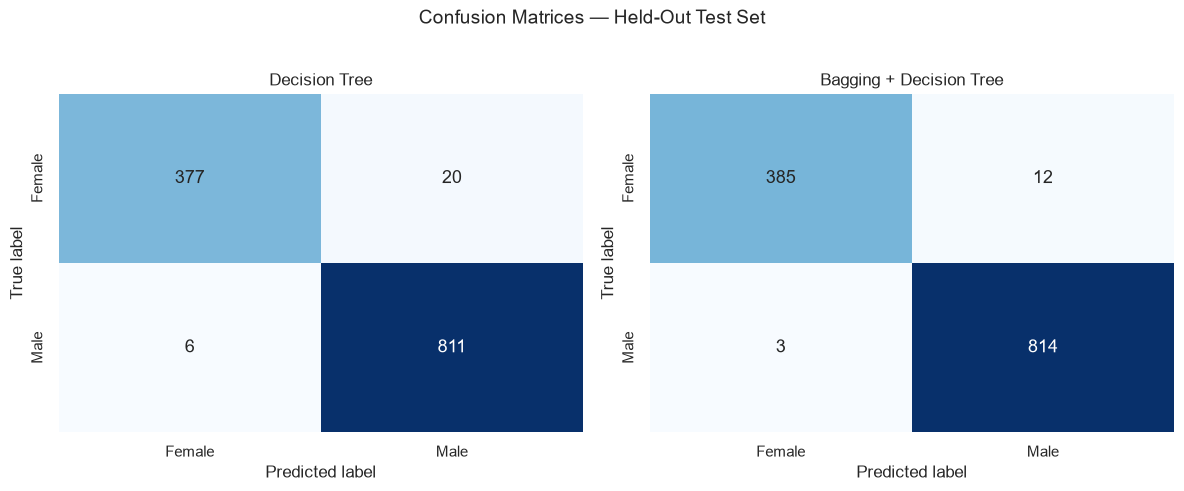

,Female correctly predicted,Female predicted Male,Male predicted Female,Male correctly predicted,Total errors
Model,,,,,
Decision Tree,377,20,6,811,26
Bagging + Decision Tree,385,12,3,814,15


**Error interpretation.** The Decision Tree misclassified 20 female and 6 male test participants. The Bagging ensemble misclassified 12 female and 3 male test participants. Bagging reduced errors by 11.

In [13]:
class_order = ['Female', 'Male']
confusion_matrices = {
    name: confusion_matrix(y_test, preds, labels=class_order)
    for name, preds in test_predictions.items()
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (model_name, cm) in zip(axes, confusion_matrices.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=class_order, yticklabels=class_order, ax=ax,
                annot_kws={'size': 13})
    ax.set(title=model_name, xlabel='Predicted label', ylabel='True label')
fig.suptitle('Confusion Matrices — Held-Out Test Set', fontsize=14, y=1.02)
fig.tight_layout()
plt.show()

rows = []
for model_name, cm in confusion_matrices.items():
    rows.append({
        'Model': model_name,
        'Female correctly predicted': int(cm[0, 0]),
        'Female predicted Male': int(cm[0, 1]),
        'Male predicted Female': int(cm[1, 0]),
        'Male correctly predicted': int(cm[1, 1]),
        'Total errors': int(cm[0, 1] + cm[1, 0]),
    })
error_table = pd.DataFrame(rows).set_index('Model')
display(error_table)

base_errors = error_table.loc['Decision Tree', 'Total errors']
bag_errors = error_table.loc['Bagging + Decision Tree', 'Total errors']
if bag_errors < base_errors:
    comparison = f'Bagging reduced errors by {base_errors - bag_errors}.'
elif bag_errors > base_errors:
    comparison = f'Bagging increased errors by {bag_errors - base_errors}.'
else:
    comparison = 'The two models made the same total number of errors.'

display(Markdown(
    f'**Error interpretation.** The Decision Tree misclassified '
    f'{error_table.loc["Decision Tree", "Female predicted Male"]} female and '
    f'{error_table.loc["Decision Tree", "Male predicted Female"]} male test participants. '
    f'The Bagging ensemble misclassified '
    f'{error_table.loc["Bagging + Decision Tree", "Female predicted Male"]} female and '
    f'{error_table.loc["Bagging + Decision Tree", "Male predicted Female"]} male test participants. '
    f'{comparison}'
))

### Part G — Interpretation of the confusion matrices

| Error category | Decision Tree | Bagging + Decision Tree |
|:--|--:|--:|
| Actual Female predicted Male | 20 | **12** |
| Actual Male predicted Female | 6 | **3** |
| **Total classification errors** | **26** | **15** |

The bagged ensemble made **11 fewer mistakes** than the standalone Decision Tree on the same test examples. The largest absolute reduction is for female participants classified as male (**20 → 12**), while male participants classified as female decreased from **6 → 3**. These counts provide the requested class-specific explanation in addition to aggregate test accuracy.

## 12. Additional model interpretation: feature importances

**Supplementary analysis (beyond A–G).** To describe what the fitted models rely on, the notebook displays impurity-based feature importance for the single Decision Tree and averages the importance scores of the fitted bootstrap trees. These scores come from **training-fitted models** and do not use the held-out test labels.

In the saved output, `neckcircumference` receives the largest impurity-based importance score in both models (**0.8111** for the single tree; **0.7978** for bagging). These scores describe how the models partition this dataset; they **do not establish causation** or justify using anthropometry to determine an individual's gender identity. Correlated measurements can distribute importance across one another.

This section does not change the pre-selected features, model settings, or final test evaluations.

Top 15 features by Bagging importance (training-fitted models):


,Decision Tree,Bagging + Decision Tree
neckcircumference,0.8111,0.7978
hipbreadthsitting,0.0717,0.0582
biacromialbreadth,0.0442,0.0503
chestheight,0.0064,0.0133
buttockcircumference,0.0076,0.0094
bicristalbreadth,0.0046,0.0066
lateralmalleolusheight,0.0072,0.0057
handcircumference,0.0026,0.0053
shouldercircumference,0.0000,0.0038
crotchlengthomphalion,0.0096,0.0037


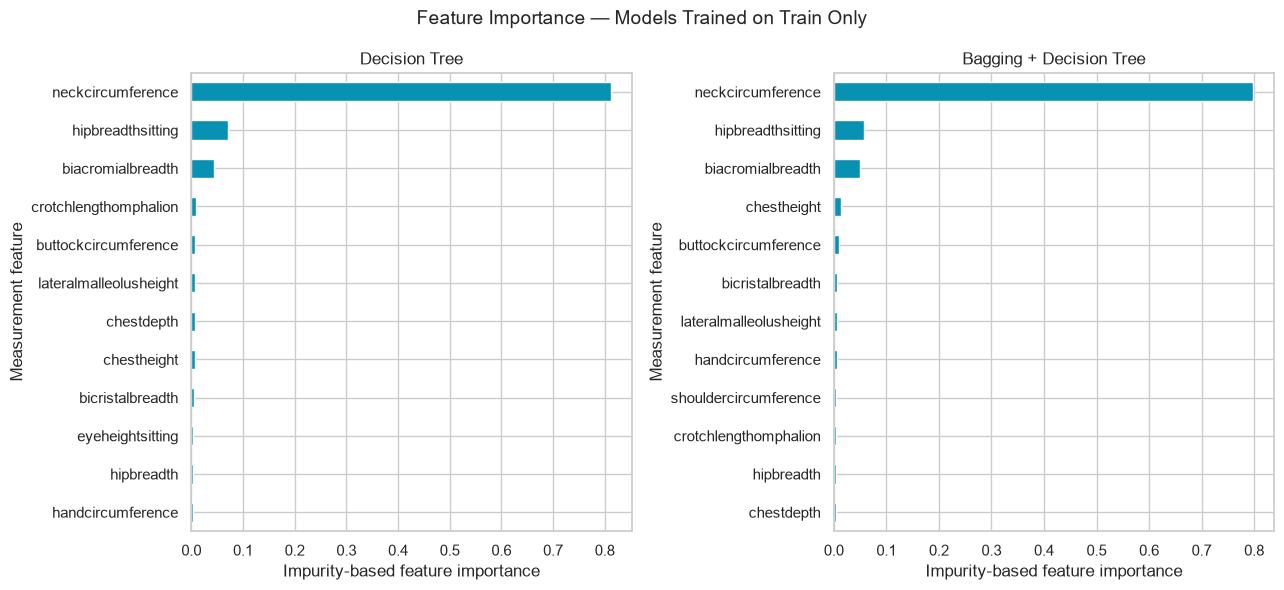

In [14]:
tree_importance = pd.Series(
    models['Decision Tree'].feature_importances_,
    index=X_train.columns, name='Decision Tree'
)

bagging_model = models['Bagging + Decision Tree']
bagging_scores = np.zeros(X_train.shape[1], dtype=float)
for fitted_tree, feature_indices in zip(bagging_model.estimators_, bagging_model.estimators_features_):
    np.add.at(bagging_scores, feature_indices, fitted_tree.feature_importances_)
bagging_scores /= len(bagging_model.estimators_)
bagging_importance = pd.Series(
    bagging_scores, index=X_train.columns, name='Bagging + Decision Tree'
)

importance_table = pd.concat([tree_importance, bagging_importance], axis=1)
print('Top 15 features by Bagging importance (training-fitted models):')
display(importance_table.sort_values('Bagging + Decision Tree', ascending=False).head(15).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, model_name in zip(axes, importance_table.columns):
    top_features = importance_table[model_name].nlargest(12).sort_values()
    top_features.plot.barh(ax=ax, color='#0891b2')
    ax.set(title=model_name, xlabel='Impurity-based feature importance', ylabel='Measurement feature')
fig.suptitle('Feature Importance — Models Trained on Train Only', fontsize=14)
fig.tight_layout()
plt.show()

## 13. Evidence-based discussion and conclusion

The next code cell creates its conclusion dynamically from the notebook's fitted models and stored evaluation tables. It summarizes the dataset preparation, the training/test split, the height findings, the model comparison, minority-class recall, and the limits of interpretation.

**Reading the result:** The important finding is not simply that a bagged model scores highly; it is whether its improvement over the **single-tree baseline** is supported by the held-out accuracy and the direction of the confusion-matrix errors. The results describe this specific ANSUR II sample and this fixed evaluation procedure, not a universal guarantee of bagging performance.

In [15]:
dt_accuracy = test_results.loc['Decision Tree', 'Accuracy']
bag_accuracy = test_results.loc['Bagging + Decision Tree', 'Accuracy']
diff_pp = 100 * (bag_accuracy - dt_accuracy)
dt_macro = test_results.loc['Decision Tree', 'Macro F1']
bag_macro = test_results.loc['Bagging + Decision Tree', 'Macro F1']

if diff_pp > 0:
    accuracy_statement = f'Bagging improved test accuracy by {diff_pp:.2f} percentage points.'
elif diff_pp < 0:
    accuracy_statement = f'Bagging decreased test accuracy by {-diff_pp:.2f} percentage points.'
else:
    accuracy_statement = 'Both models obtained identical test accuracy.'

minority_recalls = {
    name: report['Female']['recall'] for name, report in per_class_reports.items()
}

conclusion = f"""### Evidence-based conclusion

- **Dataset and cleaning:** The supplied ANSUR II files contain {len(df):,} participants and {len(measurement_features)} original anthropometric predictors. The only necessary structural correction was harmonizing the subject identifier name before concatenating the files. No exact duplicate rows or repeated subject IDs were found, and the chosen measurements had no missing training values; hence no imputation or row deletion was performed.
- **Leakage prevention:** The 80/20 stratified split preceded train-based statistical inspection and all model training. No test values informed preprocessing, hyperparameter choices, or feature selection; cross-validation was restricted to Train.
- **Height distribution:** Training-set mean heights were {height_summary.loc['Female', 'mean']:.2f} cm for female participants and {height_summary.loc['Male', 'mean']:.2f} cm for male participants. More male records make the count-based histogram generally taller, while the higher male mean shifts the male distribution to the right.
- **Held-out model performance:** The Decision Tree achieved **{dt_accuracy:.4f} accuracy ({dt_accuracy * 100:.2f}%)** and **{dt_macro:.4f} macro F1**. The Bagging ensemble achieved **{bag_accuracy:.4f} accuracy ({bag_accuracy * 100:.2f}%)** and **{bag_macro:.4f} macro F1**. {accuracy_statement}
- **Class imbalance:** Training labels are moderately imbalanced ({training_percent.loc['Male']:.1f}% male vs. {training_percent.loc['Female']:.1f}% female). Female recall on Test was **{minority_recalls['Decision Tree']:.4f}** for the single tree and **{minority_recalls['Bagging + Decision Tree']:.4f}** for Bagging. SMOTE was not introduced because this assignment's primary goal is an uncontaminated comparison of bagging versus a single tree; any imbalance intervention would require a separately validated training-only experiment.
- **Limitations:** The sample comes from a military survey rather than a representative sample of the global population. Anthropometric variables have overlapping distributions across the two dataset labels; model predictions cannot determine gender identity. Reported hold-out performance is specific to this sample and the fixed experimental protocol.
- **Potential future work:** Compare tuned tree depth and minimum leaf size using nested or train-only validation, inspect subgroup generalization where appropriate, and test weighting or resampling strictly within training folds if class-wise recall warrants it. The held-out test partition should remain reserved for unbiased final assessment.

"""
display(Markdown(conclusion))

### Evidence-based conclusion

- **Dataset and cleaning:** The supplied ANSUR II files contain 6,068 participants and 93 original anthropometric predictors. The only necessary structural correction was harmonizing the subject identifier name before concatenating the files. No exact duplicate rows or repeated subject IDs were found, and the chosen measurements had no missing training values; hence no imputation or row deletion was performed.
- **Leakage prevention:** The 80/20 stratified split preceded train-based statistical inspection and all model training. No test values informed preprocessing, hyperparameter choices, or feature selection; cross-validation was restricted to Train.
- **Height distribution:** Training-set mean heights were 162.83 cm for female participants and 175.58 cm for male participants. More male records make the count-based histogram generally taller, while the higher male mean shifts the male distribution to the right.
- **Held-out model performance:** The Decision Tree achieved **0.9786 accuracy (97.86%)** and **0.9754 macro F1**. The Bagging ensemble achieved **0.9876 accuracy (98.76%)** and **0.9859 macro F1**. Bagging improved test accuracy by 0.91 percentage points.
- **Class imbalance:** Training labels are moderately imbalanced (67.3% male vs. 32.7% female). Female recall on Test was **0.9496** for the single tree and **0.9698** for Bagging. SMOTE was not introduced because this assignment's primary goal is an uncontaminated comparison of bagging versus a single tree; any imbalance intervention would require a separately validated training-only experiment.
- **Limitations:** The sample comes from a military survey rather than a representative sample of the global population. Anthropometric variables have overlapping distributions across the two dataset labels; model predictions cannot determine gender identity. Reported hold-out performance is specific to this sample and the fixed experimental protocol.
- **Potential future work:** Compare tuned tree depth and minimum leaf size using nested or train-only validation, inspect subgroup generalization where appropriate, and test weighting or resampling strictly within training folds if class-wise recall warrants it. The held-out test partition should remain reserved for unbiased final assessment.



---

## Reproducibility, academic integrity, and handoff

**Execution order.** Run the notebook from top to bottom with the supplied **female and male ANSUR II CSV files** available in the working directory (or in `/mnt/data`, as supported by the original loader). Required packages are `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`, and `IPython`.

**Recorded experimental settings.** The train/test split is **80/20**, stratified by `Gender`, with seed **42**. The baseline is a single Decision Tree; the ensemble contains **100 bootstrapped Decision Trees** using `BaggingClassifier`. The ensemble comparison uses training-only stratified cross-validation and a reserved held-out test set.

**Scientific limitations.** ANSUR II represents a particular sample of U.S. military personnel, not a random sample of all people. The groups' measured height distributions overlap, and the trained classifiers should not be interpreted as tools for determining gender identity outside the source dataset. Test accuracy and feature importance are descriptive of the measured prediction task.

**Notebook preservation.** Existing Python code cells and their saved outputs have been preserved. The additional narrative is **Markdown-only**: it does not retrain, replace, or modify any classifier. Results can differ if the data files or software environment change.
